# Task 2 - Ising spin-glass optimisation of the 20-stock portfolio
Follows `Task2_Ising_Roadmap.docx` step by step. Needs only `adj_close_wide.csv` (optional: `pip install dimod dwave-samplers` for the two cross-checks).

## Step 1 - Freeze the inputs
One shared settings cell: same data, mu, Sigma, lambda = 5.1422, k = 6, P = 0.0256 as Task 1.

In [1]:
# TASK 2 | STEP 1 - Shared settings (frozen inputs, identical to Task 1)
# Same data, mu, Sigma, lambda, k and P as Task 1. Any difference in later results can therefore
# come only from the Ising formulation or the solver.
import os, time, itertools, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from IPython.display import display

warnings.filterwarnings("ignore")
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

# ----------------------------- settings (same values as Task 1) -----------------------------
DATA_FILE   = next(p for p in ["us_stock_data/adj_close_wide.csv", "adj_close_wide.csv",
                               "/mnt/user-data/uploads/adj_close_wide.csv"] if os.path.exists(p))
OUT_DIR     = "ising_outputs"
START, END  = "2000-01-01", "2026-01-01"
TD          = 252
RF          = 0.0
MAX_W       = 0.30            # only used for lambda (max-Sharpe) and the efficient-frontier curve, as in Task 1
SEED        = 42
K           = 6               # number of stocks held
MC_N, MC_RUNS, MC_SEED = 5000, 200, SEED + 7
os.makedirs(OUT_DIR, exist_ok=True)
def savefig(name):
    plt.savefig(f"{OUT_DIR}/{name}.png", dpi=300, bbox_inches="tight")

# ----------------------------- data, mu, Sigma (computed once) ------------------------------
prices  = pd.read_csv(DATA_FILE, index_col="Date", parse_dates=True).sort_index().loc[START:END]
returns = prices.pct_change().iloc[1:].dropna()
tickers = list(returns.columns)
N = len(tickers)
mu    = returns.mean().to_numpy() * TD
Sigma = returns.cov().to_numpy() * TD
assert np.all(np.linalg.eigvalsh(Sigma) > 0)
print(f"{N} stocks | {returns.index[0].date()} to {returns.index[-1].date()} | {len(returns)} daily returns")

# ----------------------------- Task 1 helper functions (unchanged) --------------------------
def equal_weight(n):
    return np.full(n, 1.0 / n)

def _slsqp(fun, jac, n, cap, starts):
    cons = [{"type": "eq", "fun": lambda w: np.sum(w) - 1.0, "jac": lambda w: np.ones(n)}]
    best = None
    for w0 in starts:
        res = minimize(fun, w0, jac=jac, method="SLSQP", bounds=[(0.0, cap)] * n,
                       constraints=cons, options={"maxiter": 1000, "ftol": 1e-12})
        if res.success and (best is None or res.fun < best.fun):
            best = res
    if best is None:
        return equal_weight(n)
    w = np.clip(best.x, 0.0, cap)
    return w / w.sum()

def min_variance(Sigma, cap):
    n = len(Sigma)
    return _slsqp(lambda w: w @ Sigma @ w, lambda w: 2 * Sigma @ w, n, cap, [equal_weight(n)])

def mean_variance(mu, Sigma, gamma, cap):
    n = len(mu)
    return _slsqp(lambda w: 0.5 * gamma * w @ Sigma @ w - mu @ w, lambda w: gamma * Sigma @ w - mu,
                  n, cap, [equal_weight(n), min_variance(Sigma, cap)])

def max_sharpe(mu, Sigma, cap, rf=RF):
    n = len(mu)
    def fun(w):
        return -(mu @ w - rf) / np.sqrt(w @ Sigma @ w)
    def jac(w):
        s = np.sqrt(w @ Sigma @ w)
        return -(mu / s - (mu @ w - rf) * (Sigma @ w) / s ** 3)
    return _slsqp(fun, jac, n, cap, [equal_weight(n), min_variance(Sigma, cap)])

def mv_objective(w, mu, Sigma, gamma):
    return 0.5 * gamma * w @ Sigma @ w - mu @ w

def port_stats(w, mu=mu, Sigma=Sigma):
    """(expected return, variance, volatility, Sharpe)"""
    ret, var = float(mu @ w), float(w @ Sigma @ w)
    return ret, var, np.sqrt(var), (ret - RF) / np.sqrt(var)

def frontier_points(mu, Sigma, cap, n_pts=80):
    """Long-only efficient frontier. Returns arrays (variance, return)."""
    n = len(mu)
    w_min = min_variance(Sigma, cap)
    order, w_hi, left = np.argsort(-mu), np.zeros(n), 1.0
    for i in order:
        take = min(cap, left); w_hi[i] = take; left -= take
        if left <= 1e-12: break
    pts = []
    for tr in np.linspace(mu @ w_min, mu @ w_hi, n_pts)[:-1]:
        cons = [{"type": "eq", "fun": lambda w: np.sum(w) - 1.0, "jac": lambda w: np.ones(n)},
                {"type": "eq", "fun": lambda w, tr=tr: mu @ w - tr, "jac": lambda w: mu}]
        res = minimize(lambda w: w @ Sigma @ w, w_min, jac=lambda w: 2 * Sigma @ w, method="SLSQP",
                       bounds=[(0.0, cap)] * n, constraints=cons, options={"maxiter": 1000, "ftol": 1e-12})
        if res.success:
            pts.append((res.fun, tr))
    pts.append((w_hi @ Sigma @ w_hi, mu @ w_hi))
    pts = np.array(pts)
    pts = pts[np.argsort(pts[:, 0])]
    return pts[:, 0], np.maximum.accumulate(pts[:, 1])

def repair_units(u, f, total, cap_u):
    """Greedy repair: add / remove single units until sum(u) == total, always taking the best objective."""
    u = u.copy()
    while u.sum() > total:
        cand = np.flatnonzero(u > 0)
        vals = []
        for i in cand:
            u[i] -= 1; vals.append(f(u)); u[i] += 1
        u[cand[int(np.argmin(vals))]] -= 1
    while u.sum() < total:
        cand = np.flatnonzero(u < cap_u)
        vals = []
        for i in cand:
            u[i] += 1; vals.append(f(u)); u[i] -= 1
        u[cand[int(np.argmin(vals))]] += 1
    return u

def decode_select(X, E, k, mu, Sigma, gamma, top=10):
    """Best equal-weight portfolio among the `top` lowest-energy samples (after repair if needed)."""
    f = lambda uu: mv_objective(uu / k, mu, Sigma, gamma)
    best_u, best_f = None, np.inf
    for r in np.argsort(E)[:top]:
        u = repair_units(X[r].astype(int), f, k, 1)
        if f(u) < best_f:
            best_u, best_f = u, f(u)
    return best_u / k, dict(feasible_rate=float((X.sum(axis=1) == k).mean()), units=best_u)

# ----------------------------- lambda and penalty P (same recipe as Task 1) -----------------
w_maxsh = max_sharpe(mu, Sigma, MAX_W)
r_t, v_t, _, sh_t = port_stats(w_maxsh)
LAMBDA = (r_t - RF) / v_t

def mc_binary_samples(n, m, rng):
    card = rng.integers(0, n + 1, size=m)
    rank = np.argsort(np.argsort(rng.random((m, n)), axis=1), axis=1)
    return (rank < card[:, None]).astype(float)

def penalty_lower_bound(q, lin, s, k, lam):
    f = 0.5 * lam / k ** 2 * q - lin / k
    viol = (s - k) ** 2
    v_min = viol.min()
    f_from = f[viol == v_min].min()
    m = (f < f_from) & (viol > v_min)
    if not m.any():
        return 0.0
    return ((f_from - f[m]) / (viol[m] - v_min)).max()

rng_mc = np.random.default_rng(MC_SEED)
mc_p = np.zeros(MC_RUNS)
for run in range(MC_RUNS):
    Xs = mc_binary_samples(N, MC_N, rng_mc)
    mc_p[run] = penalty_lower_bound(np.einsum("ri,ij,rj->r", Xs, Sigma, Xs), Xs @ mu, Xs.sum(axis=1), K, LAMBDA)
P = mc_p.max()

obj_w = lambda w: mv_objective(w, mu, Sigma, LAMBDA)
print(f"lambda = {LAMBDA:.4f}   |   k = {K}   |   penalty P = {P:.4f}   (Task 1: lambda = 5.1422, P = 0.0256)")

# ----------------------------- QUBO of Task 1:  H(x) = x'Qx + CONST --------------------------
def build_qubo(P):
    Q = 0.5 * LAMBDA / K ** 2 * Sigma - np.diag(mu / K) + P * (np.ones((N, N)) - 2 * K * np.eye(N))
    return Q, P * K ** 2
Q, CONST = build_qubo(P)


20 stocks | 2000-01-04 to 2025-12-31 | 6538 daily returns
lambda = 5.1422   |   k = 6   |   penalty P = 0.0256   (Task 1: lambda = 5.1422, P = 0.0256)


## Step 2 - Convert QUBO to Ising
Substituting x = (1 + s) / 2 gives  H(s) = sum_{i<j} J_ij s_i s_j + sum_i h_i s_i + C  with  J_ij = Q_ij / 2,  h_i = 1/2 sum_j Q_ij,  C = 1/4 sum_ij Q_ij + 1/4 sum_i Q_ii + P k^2.

In [2]:
# TASK 2 | STEP 2 - QUBO -> Ising (x = (1 + s) / 2, bit 1 = stock selected = spin +1)
#   H(s) = sum_{i<j} J_ij s_i s_j + sum_i h_i s_i + C
#   J_ij = Q_ij / 2        h_i = 1/2 * sum_j Q_ij        C = 1/4 sum_ij Q_ij + 1/4 sum_i Q_ii + P*k^2
def qubo_to_ising(Q, const):
    Qs = 0.5 * (Q + Q.T)
    J = 0.5 * Qs.copy(); np.fill_diagonal(J, 0.0)          # full symmetric matrix, each pair (i<j) counted once in H
    h = 0.5 * Qs.sum(axis=1)
    C = 0.25 * Qs.sum() + 0.25 * np.trace(Qs) + const
    return J, h, C

J, h, C = qubo_to_ising(Q, CONST)
M_FIXED = 2 * K - N                                         # fixed magnetisation: sum(s) = 2k - N
iu = np.triu_indices(N, 1)
print(f"Spins: {N} | couplings J_ij: {len(iu[0])} (fully connected) | constant C = {C:.6f}")
print(f"Constraint 'exactly k stocks'  ->  sum(s) = 2k - N = {M_FIXED}  ({K} spins up, {N - K} spins down)\n")

# how to read it as a spin glass
Jp = J[iu]
print(f"J_ij > 0 (antiferromagnetic): {(Jp > 0).sum()} of {len(Jp)} pairs   |   J_ij < 0 (ferromagnetic): {(Jp < 0).sum()}")
print(f"J_ij range: [{Jp.min():.5f}, {Jp.max():.5f}]   mean {Jp.mean():.5f}   std {Jp.std():.5f}")
print(f"  of which the penalty alone contributes P/2 = {P / 2:.5f} to every pair; the covariance part "
      f"lambda/(4k^2) * Sigma_ij ranges over [{(LAMBDA / (4 * K**2) * Sigma[iu]).min():.5f}, {(LAMBDA / (4 * K**2) * Sigma[iu]).max():.5f}]")
print(f"local fields h_i: range [{h.min():.5f}, {h.max():.5f}]   (all positive: the penalty term P*(N-2k)/2 = {P * (N - 2 * K) / 2:.5f} "
      f"is common to every spin; the return term -mu_i/(2k) only shifts it per stock)")
display(pd.DataFrame({"h_i": h, "mu_i (%)": mu * 100, "sum_j J_ij": J.sum(axis=1)}, index=tickers).round(5))


Spins: 20 | couplings J_ij: 190 (fully connected) | constant C = 0.624832
Constraint 'exactly k stocks'  ->  sum(s) = 2k - N = -8  (6 spins up, 14 spins down)

J_ij > 0 (antiferromagnetic): 190 of 190 pairs   |   J_ij < 0 (ferromagnetic): 0
J_ij range: [0.01317, 0.01768]   mean 0.01424   std 0.00093
  of which the penalty alone contributes P/2 = 0.01281 to every pair; the covariance part lambda/(4k^2) * Sigma_ij ranges over [0.00036, 0.00487]
local fields h_i: range [0.10808, 0.14399]   (all positive: the penalty term P*(N-2k)/2 = 0.10245 is common to every spin; the return term -mu_i/(2k) only shifts it per stock)


,h_i,mu_i (%),sum_j J_ij
MSFT,0.12179,14.55496,0.27158
AAPL,0.11225,30.00298,0.27283
NVDA,0.11582,46.79913,0.28324
AMZN,0.11994,26.95258,0.27475
INTC,0.13381,9.36993,0.27692
WMT,0.11092,10.67335,0.25873
KO,0.11073,8.38165,0.25711
DIS,0.12464,10.88921,0.27126
PG,0.10941,8.63262,0.25594
IBM,0.11978,9.70187,0.26633


## Step 3 - Build the Ising model in code and validate it
Hand-coded formulas versus `dimod` (`bqm.to_ising()`), then Ising energy = QUBO energy on all 2^20 states, and = Markowitz objective on the 38,760 feasible states.

In [3]:
# TASK 2 | STEP 3 - Build the Ising model in code and validate it
# Route A: hand-coded formulas of Step 2 (above).  Route B: dimod BinaryQuadraticModel(...).to_ising().
try:
    import dimod
    bqm = dimod.BinaryQuadraticModel.from_qubo({(i, j): (Q[i, j] + Q[j, i] if i != j else Q[i, i])
                                                for i in range(N) for j in range(i, N)}, offset=CONST)
    h_d, J_d, off_d = bqm.to_ising()
    h_dimod = np.array([h_d[i] for i in range(N)])
    J_dimod = np.zeros((N, N))
    for (i, j), v in J_d.items():
        J_dimod[i, j] = J_dimod[j, i] = v
    print("dimod route vs hand-coded route:")
    print(f"  max |h - h_dimod| = {np.abs(h - h_dimod).max():.2e} | max |J - J_dimod| = {np.abs(J - J_dimod).max():.2e}"
          f" | |C - offset| = {abs(C - off_d):.2e}")
    assert np.allclose(h, h_dimod) and np.allclose(J, J_dimod) and np.isclose(C, off_d)
except ImportError:
    print("dimod is not installed here -> dimod cross-check skipped (run `pip install dimod` and re-run this cell).")

def ising_energy(S, J=J, h=h, C=C):
    """S: (m, N) array of +-1 spins -> energies (m,).   H = 1/2 s'Js + h's + C   (J symmetric, zero diagonal)"""
    return 0.5 * np.einsum("mi,ij,mj->m", S, J, S) + S @ h + C

def qubo_energy(X, Q=Q, const=CONST):
    return np.einsum("mi,ij,mj->m", X, Q, X) + const

def bits(idx, n=N):
    return ((idx[:, None] >> np.arange(n)) & 1).astype(float)

# (a) all 2^20 states: Ising energy = QUBO energy
t0 = time.time()
CHUNK, total = 1 << 16, 1 << N
max_err, e_min, s_min = 0.0, np.inf, None
n_feas, max_err_feas = 0, 0.0
for start in range(0, total, CHUNK):
    X = bits(np.arange(start, min(start + CHUNK, total)))
    S = 2 * X - 1
    e_is, e_qu = ising_energy(S), qubo_energy(X)
    max_err = max(max_err, np.abs(e_is - e_qu).max())
    j = int(np.argmin(e_is))
    if e_is[j] < e_min:
        e_min, s_min = float(e_is[j]), S[j].copy()
    # (b) feasible states (exactly k stocks): Ising energy = Markowitz objective  lambda/2 w'Sigma w - mu'w, w = x/k
    f = X.sum(axis=1) == K
    if f.any():
        W = X[f] / K
        obj = 0.5 * LAMBDA * np.einsum("mi,ij,mj->m", W, Sigma, W) - W @ mu
        max_err_feas = max(max_err_feas, np.abs(e_is[f] - obj).max()); n_feas += int(f.sum())
print(f"(a) all {total:,} states : max |E_Ising - E_QUBO| = {max_err:.2e}")
print(f"(b) {n_feas:,} feasible states (exactly {K} stocks): max |E_Ising - Markowitz objective| = {max_err_feas:.2e}")
assert max_err < 1e-10 and max_err_feas < 1e-10 and n_feas == 38760
print(f"VALIDATION PASSED  ({time.time() - t0:.1f} s)")
print(f"lowest Ising energy over all 2^{N} states: {e_min:.6f} | magnetisation of that state: {int(s_min.sum())} (must be {M_FIXED})")


dimod route vs hand-coded route:
  max |h - h_dimod| = 8.33e-17 | max |J - J_dimod| = 0.00e+00 | |C - offset| = 1.11e-16
(a) all 1,048,576 states : max |E_Ising - E_QUBO| = 6.22e-15
(b) 38,760 feasible states (exactly 6 stocks): max |E_Ising - Markowitz objective| = 1.62e-15
VALIDATION PASSED  (1.7 s)
lowest Ising energy over all 2^20 states: -0.111866 | magnetisation of that state: -8 (must be -8)


## Step 4a - Exact reference (brute force over all states with sum(s) = -8)

In [4]:
# TASK 2 | STEP 4a - Exact reference: brute force over all spin states with sum(s) = 2k - N = -8
t0 = time.time()
combos = np.array(list(itertools.combinations(range(N), K)))            # which spins are up
S_all = -np.ones((len(combos), N)); S_all[np.arange(len(combos))[:, None], combos] = 1.0
E_all = ising_energy(S_all)
assert np.all(S_all.sum(axis=1) == M_FIXED)
t_exact = time.time() - t0

order = np.argsort(E_all)
E_GS, S_GS = float(E_all[order[0]]), S_all[order[0]]
sel_gs = np.flatnonzero(S_GS > 0)
print(f"{len(combos):,} states with sum(s) = {M_FIXED} enumerated in {t_exact:.2f} s")
print(f"Ising ground state energy E_GS = {E_GS:.6f}   (all 2^20 states gave {e_min:.6f}: "
      f"same state = {bool(np.isclose(E_GS, e_min) and np.array_equal(S_GS, s_min))})")
print("Ground state, spins up = " + ", ".join(tickers[i] for i in sel_gs))

top10 = pd.DataFrame({"Spins up (stocks)": [", ".join(tickers[i] for i in combos[o]) for o in order[:10]],
                      "Ising energy": E_all[order[:10]],
                      "Gap to ground state": E_all[order[:10]] - E_GS})
display(top10.round(6))


38,760 states with sum(s) = -8 enumerated in 0.12 s
Ising ground state energy E_GS = -0.111866   (all 2^20 states gave -0.111866: same state = True)
Ground state, spins up = AAPL, NVDA, MCD, JNJ, UNH, BRK-B


,Spins up (stocks),Ising energy,Gap to ground state
0,"AAPL, NVDA, MCD, JNJ, UNH, BRK-B",-0.111866,0.000000
1,"AAPL, NVDA, PG, MCD, JNJ, UNH",-0.109552,0.002315
2,"AAPL, NVDA, WMT, MCD, JNJ, UNH",-0.109347,0.002519
3,"AAPL, NVDA, PG, MCD, UNH, BRK-B",-0.109312,0.002555
4,"AAPL, NVDA, PG, JNJ, UNH, BRK-B",-0.108782,0.003084
5,"AAPL, NVDA, WMT, MCD, UNH, BRK-B",-0.108719,0.003147
6,"AAPL, NVDA, WMT, JNJ, UNH, BRK-B",-0.108718,0.003149
7,"AAPL, NVDA, KO, MCD, JNJ, UNH",-0.108080,0.003787
8,"AAPL, NVDA, KO, MCD, UNH, BRK-B",-0.107501,0.004365
9,"AAPL, NVDA, KO, JNJ, UNH, BRK-B",-0.107249,0.004617


## Step 4b - Ising simulated annealing
Metropolis single-spin-flip annealing on h and J, with the Task 1 budgets (128 chains x 150 sweeps, 1000 reads x 1000 sweeps). A variant with two-spin moves (the same moves as the Task 1 SA) is added so that the comparison with the Task 1 SA is like-for-like.

In [5]:
# TASK 2 | STEP 4b - Ising simulated annealing: Metropolis single-spin-flip dynamics on h and J
#   local field  f_i = h_i + sum_j J_ij s_j     flip s_i -> -s_i costs   dE = -2 s_i f_i
#   (the same energy change as the corresponding bit flip of the QUBO)
#   n_chains independent chains are annealed in parallel; temperature falls geometrically over n_sweeps sweeps
#   (start temperature = 0.1 x median |dE| of random states, end = start x 1e-4; the rule used in the Task 1 SA)
#   pair_moves=True adds, after the single flips of every sweep, n two-spin moves (flip spins i and k together;
#   with one up and one down spin this swaps a stock in for a stock out and keeps sum(s) fixed). These are the same
#   moves as the two-bit moves of the Task 1 SA, so this variant is "your own SA adapted to spins".
#   two-spin move cost:  dE = -2 s_i f_i - 2 s_k f_k + 4 J_ik s_i s_k
def ising_sa(J, h, C, n_chains=128, n_sweeps=150, rng=None, t_scale=0.1, pair_moves=False):
    """Returns final spin states (chains x n) and their energies."""
    rng = rng if rng is not None else np.random.default_rng(SEED)
    n = len(h)
    S = rng.choice([-1.0, 1.0], size=(n_chains, n))
    F = S @ J + h                                                   # local fields of every chain
    t_hi = t_scale * np.median(np.abs(-2 * S * F))
    temps = np.geomspace(t_hi, t_hi * 1e-4, n_sweeps)
    for T in temps:
        U = rng.random((n, n_chains))
        for j, i in enumerate(rng.permutation(n)):
            dE = -2 * S[:, i] * F[:, i]
            acc = (dE <= 0) | (U[j] < np.exp(-np.maximum(dE, 0) / T))
            if acc.any():
                m = -2 * S[:, i] * acc                                  # change of s_i where the flip is accepted
                S[:, i] += m
                F += m[:, None] * J[i]
        if pair_moves:
            U2 = rng.random((n, n_chains))
            pairs = np.array([rng.choice(n, 2, replace=False) for _ in range(n)])
            for j, (i, k) in enumerate(pairs):
                dE = -2 * S[:, i] * F[:, i] - 2 * S[:, k] * F[:, k] + 4 * J[i, k] * S[:, i] * S[:, k]
                acc = (dE <= 0) | (U2[j] < np.exp(-np.maximum(dE, 0) / T))
                if acc.any():
                    mi, mk = -2 * S[:, i] * acc, -2 * S[:, k] * acc
                    S[:, i] += mi; S[:, k] += mk
                    F += mi[:, None] * J[i] + mk[:, None] * J[k]
    return S, ising_energy(S, J, h, C)

# one run of each budget used in Task 1:  single-spin flips, and single flips + two-spin moves
RUNS, RUNS_PAIR = {}, {}
for chains, sweeps, pm in [(128, 150, False), (1000, 1000, False), (128, 150, True)]:
    t0 = time.time()
    S_run, E_run = ising_sa(J, h, C, chains, sweeps, rng=np.random.default_rng(SEED), pair_moves=pm)
    dt = time.time() - t0
    (RUNS_PAIR if pm else RUNS)[(chains, sweeps)] = (S_run, E_run, dt)
    feas = S_run.sum(axis=1) == M_FIXED
    hit = np.isclose(E_run, E_GS, atol=1e-10)
    print(f"{chains:>4} chains x {sweeps:>4} sweeps, {'+ two-spin moves' if pm else 'single flips   '}: {dt:5.2f} s | lowest energy {E_run.min():.6f} (exact {E_GS:.6f}) | "
          f"feasible reads {feas.mean() * 100:5.1f}% | reads at the ground state {hit.mean() * 100:5.1f}%")


 128 chains x  150 sweeps, single flips   :  0.04 s | lowest energy -0.111866 (exact -0.111866) | feasible reads 100.0% | reads at the ground state   1.6%
1000 chains x 1000 sweeps, single flips   :  0.57 s | lowest energy -0.111866 (exact -0.111866) | feasible reads 100.0% | reads at the ground state   3.9%
 128 chains x  150 sweeps, + two-spin moves:  0.11 s | lowest energy -0.111866 (exact -0.111866) | feasible reads 100.0% | reads at the ground state 100.0%


## Step 5 - Decode and evaluate
x = (1 + s) / 2; samples with exactly k stocks are kept (repair otherwise); every portfolio is scored with the Task 1 `port_stats` and `mv_objective`.

In [6]:
# TASK 2 | STEP 5 - Decode (x = (1 + s) / 2), keep exactly-k samples (repair otherwise) and score every portfolio
# with the SAME port_stats / mv_objective functions as Task 1.
def decode_spins(S):
    return (1 + S) / 2

def score(w):
    r_, v_, s_, h_ = port_stats(w)
    return dict(ret=r_ * 100, var=v_, vol=s_ * 100, sharpe=h_, obj=obj_w(w))

# Ising + exhaustive search (ground state)
X_gs = decode_spins(S_GS[None, :])
w_ising_exact, _ = decode_select(X_gs, np.array([E_GS]), K, mu, Sigma, LAMBDA)

# Ising + simulated annealing (best of the 128 x 150 run and of the 1000 x 1000 run)
w_ising_sa, info_sa = {}, {}
for key, (S_run, E_run, dt) in RUNS.items():
    w_ising_sa[key], info_sa[key] = decode_select(decode_spins(S_run), E_run, K, mu, Sigma, LAMBDA)

w_ising_pair, _ = decode_select(decode_spins(RUNS_PAIR[(128, 150)][0]), RUNS_PAIR[(128, 150)][1], K, mu, Sigma, LAMBDA)

# Task 1 reference: the QUBO + own SA code of Task 1 (unchanged), same seed as Task 1
def simulated_annealing(Q, n_chains=128, n_sweeps=150, rng=None, t_hi=None, t_lo=None, t_scale=0.1):
    rng = rng if rng is not None else np.random.default_rng(SEED)
    Q = 0.5 * (Q + Q.T)
    n = Q.shape[0]
    d = np.diag(Q).copy()
    off = Q - np.diag(d)
    X = rng.integers(0, 2, size=(n_chains, n)).astype(float)
    H = X @ off
    E = np.einsum("ri,ri->r", X @ Q, X)
    if t_hi is None:
        t_hi = t_scale * np.median(np.abs((1 - 2 * X) * (d + 2 * H)))
    if t_lo is None:
        t_lo = t_hi * 1e-4
    temps = np.geomspace(t_hi, t_lo, n_sweeps)
    for s, T in enumerate(temps):
        U1 = rng.random((n, n_chains))
        for j, i in enumerate(rng.permutation(n)):
            delta = 1 - 2 * X[:, i]
            dE = delta * (d[i] + 2 * H[:, i])
            acc = (dE <= 0) | (U1[j] < np.exp(-np.maximum(dE, 0) / T))
            if acc.any():
                m = acc * delta
                X[:, i] += m; H += m[:, None] * off[i]; E += acc * dE
        U2 = rng.random((n, n_chains))
        pairs = np.array([rng.choice(n, 2, replace=False) for _ in range(n)])
        for j, (i, k) in enumerate(pairs):
            di, dk = 1 - 2 * X[:, i], 1 - 2 * X[:, k]
            dE = di * (d[i] + 2 * H[:, i]) + dk * (d[k] + 2 * H[:, k]) + 2 * off[i, k] * di * dk
            acc = (dE <= 0) | (U2[j] < np.exp(-np.maximum(dE, 0) / T))
            if acc.any():
                mi, mk = acc * di, acc * dk
                X[:, i] += mi; X[:, k] += mk
                H += mi[:, None] * off[i] + mk[:, None] * off[k]; E += acc * dE
    return X, np.einsum("ri,ri->r", X @ Q, X)

X_q, E_q = simulated_annealing(Q, 128, 150, rng=np.random.default_rng(SEED + 1000 + K))
E_q = E_q + CONST
w_qubo_sa, _ = decode_select(X_q, E_q, K, mu, Sigma, LAMBDA)

# MIQP of Task 1 (Gurobi, k = 6, free weights): same six stocks; weights re-derived here by the convex QP on that subset
miqp_idx = np.array([tickers.index(t) for t in ["UNH", "AAPL", "JNJ", "NVDA", "MCD", "BRK-B"]])
Ss, ms = Sigma[np.ix_(miqp_idx, miqp_idx)], mu[miqp_idx]
qp = minimize(lambda x: 0.5 * LAMBDA * x @ Ss @ x - ms @ x, np.full(K, 1 / K), jac=lambda x: LAMBDA * Ss @ x - ms,
              method="SLSQP", bounds=[(0, 1)] * K, constraints=[{"type": "eq", "fun": lambda x: x.sum() - 1}],
              options={"ftol": 1e-14, "maxiter": 500})
w_miqp = np.zeros(N); w_miqp[miqp_idx] = qp.x

rows = {"MIQP (Gurobi, k = 6, free weights) [Task 1]": w_miqp,
        "QUBO + own SA (k = 6) [Task 1, rerun]": w_qubo_sa,
        "Ising + exhaustive search": w_ising_exact,
        "Ising + SA (128 chains x 150 sweeps)": w_ising_sa[(128, 150)],
        "Ising + SA (1000 reads x 1000 sweeps)": w_ising_sa[(1000, 1000)],
        "Ising + SA with two-spin moves (128 x 150)": w_ising_pair}
tab5 = pd.DataFrame({name: score(w) for name, w in rows.items()}).T
tab5.insert(0, "Portfolio", [", ".join(f"{tickers[i]} {w[i] * 100:.1f}%" for i in np.argsort(-w) if w[i] > 1e-6) for w in rows.values()])
tab5.columns = ["Portfolio", "Return %", "Variance", "Vol %", "Sharpe", "Objective"]
display(tab5.round({"Return %": 2, "Variance": 4, "Vol %": 2, "Sharpe": 3, "Objective": 4}))
print(f"MIQP weights re-derived by QP: return {tab5.iloc[0]['Return %']:.2f}%, vol {tab5.iloc[0]['Vol %']:.2f}%, Sharpe {tab5.iloc[0]['Sharpe']:.3f}, "
      f"objective {tab5.iloc[0]['Objective']:.4f}   (Task 1 notebook: 22.76 / 21.15 / 1.076 / -0.1126)")
print(f"Same stocks as the Ising ground state: Ising exhaustive = QUBO SA = all Ising SA runs -> "
      f"{len({frozenset(np.flatnonzero(w)) for w in [w_ising_exact, w_qubo_sa, w_ising_sa[(128,150)], w_ising_sa[(1000,1000)], w_ising_pair]}) == 1}")
print(f"Ising ground-state energy {E_GS:.6f} = Markowitz objective of the equal-weight portfolio {obj_w(w_ising_exact):.6f}")


,Portfolio,Return %,Variance,Vol %,Sharpe,Objective
"MIQP (Gurobi, k = 6, free weights) [Task 1]","UNH 20.3%, AAPL 19.3%, JNJ 17.7%, NVDA 16.0%, ...",22.76,0.0447,21.15,1.076,-0.1126
"QUBO + own SA (k = 6) [Task 1, rerun]","AAPL 16.7%, NVDA 16.7%, MCD 16.7%, JNJ 16.7%, ...",22.26,0.0431,20.75,1.073,-0.1119
Ising + exhaustive search,"AAPL 16.7%, NVDA 16.7%, MCD 16.7%, JNJ 16.7%, ...",22.26,0.0431,20.75,1.073,-0.1119
Ising + SA (128 chains x 150 sweeps),"AAPL 16.7%, NVDA 16.7%, MCD 16.7%, JNJ 16.7%, ...",22.26,0.0431,20.75,1.073,-0.1119
Ising + SA (1000 reads x 1000 sweeps),"AAPL 16.7%, NVDA 16.7%, MCD 16.7%, JNJ 16.7%, ...",22.26,0.0431,20.75,1.073,-0.1119
Ising + SA with two-spin moves (128 x 150),"AAPL 16.7%, NVDA 16.7%, MCD 16.7%, JNJ 16.7%, ...",22.26,0.0431,20.75,1.073,-0.1119


MIQP weights re-derived by QP: return 22.76%, vol 21.15%, Sharpe 1.076, objective -0.1126   (Task 1 notebook: 22.76 / 21.15 / 1.076 / -0.1126)
Same stocks as the Ising ground state: Ising exhaustive = QUBO SA = all Ising SA runs -> True
Ising ground-state energy -0.111866 = Markowitz objective of the equal-weight portfolio -0.111866


## Step 6 - Comparison experiments (30 seeds per solver)

In [7]:
# TASK 2 | STEP 6 - Comparison experiments: every stochastic solver repeated over 30 random seeds
N_SEEDS = 30
f_opt = E_GS                                         # exact optimum (Ising ground state = Markowitz objective of the best 6 stocks)
is_hit = lambda S: (S == S_GS).all(axis=1)           # read equals the exact optimal configuration

def run_metrics(S, E, dt):
    """S: spins (reads x N). Metrics of one run (one seed)."""
    feas = S.sum(axis=1) == M_FIXED
    w, _ = decode_select(decode_spins(S), E, K, mu, Sigma, LAMBDA)
    return {"best objective": obj_w(w), "gap to optimum": obj_w(w) - f_opt, "% reads at optimum": is_hit(S).mean() * 100,
            "% feasible reads": feas.mean() * 100, "best read = optimum": float(obj_w(w) <= f_opt + 1e-10), "runtime (s)": dt}

def repeat(label, fn):
    rows = []
    for s in range(N_SEEDS):
        t0 = time.time(); S, E = fn(np.random.default_rng(SEED + s)); dt = time.time() - t0
        rows.append(run_metrics(S, E, dt))
    return pd.DataFrame(rows)

RES = {}
RES["Ising SA, 128 chains x 150 sweeps"]   = repeat("a", lambda r: ising_sa(J, h, C, 128, 150, rng=r))
RES["Ising SA, 1000 reads x 1000 sweeps"]  = repeat("b", lambda r: ising_sa(J, h, C, 1000, 1000, rng=r))

RES["Ising SA + two-spin moves, 128 chains x 150 sweeps"] = repeat("b2", lambda r: ising_sa(J, h, C, 128, 150, rng=r, pair_moves=True))

def qubo_sa_as_spins(r):                              # Task 1 solver (bits) -> spins, so the same metrics apply
    X, E = simulated_annealing(Q, 128, 150, rng=r)
    return 2 * X - 1, E + CONST
RES["QUBO SA (Task 1 code), 128 x 150"] = repeat("c", qubo_sa_as_spins)

try:                                                  # D-Wave's classical SA sampler on the SPIN model (needs dimod + dwave-samplers)
    import dimod
    from dwave.samplers import SimulatedAnnealingSampler
    bqm_spin = dimod.BinaryQuadraticModel.from_ising({i: h[i] for i in range(N)},
                                                     {(i, j): J[i, j] for i, j in zip(*iu)}, offset=C)
    def dwave_spin(r):
        ss = SimulatedAnnealingSampler().sample(bqm_spin, num_reads=1000, num_sweeps=1000, seed=int(r.integers(2**31)))
        cols = [list(ss.variables).index(i) for i in range(N)]
        return np.array(ss.record.sample)[:, cols].astype(float), np.array(ss.record.energy)
    RES["D-Wave SA sampler on SPIN model, 1000 x 1000"] = repeat("d", dwave_spin)
except ImportError:
    print("dimod / dwave-samplers not installed here -> D-Wave sampler row skipped (pip install dimod dwave-samplers).\n")

summ = pd.DataFrame({name: {"best objective (mean)": d["best objective"].mean(),
                            "gap to optimum (max over seeds)": d["gap to optimum"].max(),
                            "seeds whose best read = optimum": f"{int(d['best read = optimum'].sum())} / {N_SEEDS}",
                            "% reads at optimum (mean)": d["% reads at optimum"].mean(),
                            "% reads at optimum (std)": d["% reads at optimum"].std(),
                            "% feasible reads (mean)": d["% feasible reads"].mean(),
                            "runtime s per run (mean)": d["runtime (s)"].mean()} for name, d in RES.items()}).T
print(f"Exact optimum: objective {f_opt:.6f}.  {N_SEEDS} seeds per solver (seeds {SEED}..{SEED + N_SEEDS - 1}).")
print("Task 1 benchmark for D-Wave local SA on the QUBO (1000 reads x 1000 sweeps): 4.3% of reads at the optimum.\n")
display(summ.round({"best objective (mean)": 6, "gap to optimum (max over seeds)": 8, "% reads at optimum (mean)": 2,
                    "% reads at optimum (std)": 2, "% feasible reads (mean)": 1, "runtime s per run (mean)": 3}))


Exact optimum: objective -0.111866.  30 seeds per solver (seeds 42..71).
Task 1 benchmark for D-Wave local SA on the QUBO (1000 reads x 1000 sweeps): 4.3% of reads at the optimum.



,best objective (mean),gap to optimum (max over seeds),seeds whose best read = optimum,% reads at optimum (mean),% reads at optimum (std),% feasible reads (mean),runtime s per run (mean)
"Ising SA, 128 chains x 150 sweeps",-0.111473,0.002555,25 / 30,1.302083,1.052832,100.0,0.032646
"Ising SA, 1000 reads x 1000 sweeps",-0.111866,0.0,30 / 30,3.783333,0.562067,100.0,0.561087
"Ising SA + two-spin moves, 128 chains x 150 sweeps",-0.111866,0.0,30 / 30,100.0,0.0,100.0,0.104937
"QUBO SA (Task 1 code), 128 x 150",-0.111866,0.0,30 / 30,100.0,0.0,100.0,0.128023
"D-Wave SA sampler on SPIN model, 1000 x 1000",-0.111866,0.0,30 / 30,3.786667,0.663186,99.216667,0.402406


### Sensitivity: number of sweeps and penalty P

In [8]:
# TASK 2 | STEP 6 (cont.) - Sensitivity to the number of sweeps and to the penalty P  (Ising SA, 1000 reads, 30 seeds)
def sa_stats(Jx, hx, Cx, sweeps, n_reads=1000):
    out = []
    for s in range(N_SEEDS):
        S, E = ising_sa(Jx, hx, Cx, n_reads, sweeps, rng=np.random.default_rng(SEED + s))
        out.append((is_hit(S).mean() * 100, (S.sum(axis=1) == M_FIXED).mean() * 100))
    out = np.array(out)
    return out[:, 0].mean(), out[:, 0].std(), out[:, 1].mean()

# (i) number of sweeps (P = 1x)
SWEEPS = [10, 50, 150, 1000]
sw = pd.DataFrame([dict(zip(["% reads at optimum (mean)", "std", "% feasible reads (mean)"], sa_stats(J, h, C, s))) for s in SWEEPS],
                  index=pd.Index(SWEEPS, name="sweeps"))
print("Sweeps (1000 reads, P = 1x):")
display(sw.round(2))

# (ii) penalty P at 0.5x, 1x, 2x (1000 reads x 1000 sweeps); the exact ground state of each Hamiltonian is found by brute force over all 2^20 spins
rows = []
for mult in [0.5, 1.0, 2.0]:
    Qm, Cm = build_qubo(mult * P); Jm, hm, Cmm = qubo_to_ising(Qm, Cm)
    e_best, s_best = np.inf, None
    for start in range(0, 1 << N, 1 << 16):
        S = 2 * bits(np.arange(start, start + (1 << 16))) - 1
        e = ising_energy(S, Jm, hm, Cmm); j = int(np.argmin(e))
        if e[j] < e_best: e_best, s_best = float(e[j]), S[j].copy()
    m_, sd_, fe_ = sa_stats(Jm, hm, Cmm, 1000)
    rows.append({"P multiplier": mult, "P": mult * P, "ground state has exactly k stocks": bool(s_best.sum() == M_FIXED),
                 "ground state = same 6 stocks": bool(np.array_equal(s_best, S_GS)),
                 "% reads at optimum (mean)": m_, "std": sd_, "% feasible reads (mean)": fe_})
pen = pd.DataFrame(rows).set_index("P multiplier")
print("\nPenalty P (1000 reads x 1000 sweeps):")
display(pen.round({"P": 5, "% reads at optimum (mean)": 2, "std": 2, "% feasible reads (mean)": 1}))


Sweeps (1000 reads, P = 1x):


,% reads at optimum (mean),std,% feasible reads (mean)
sweeps,,,
10,0.10,0.17,100.0
50,0.51,0.17,100.0
150,1.25,0.34,100.0
1000,3.78,0.55,100.0



Penalty P (1000 reads x 1000 sweeps):


,P,ground state has exactly k stocks,ground state = same 6 stocks,% reads at optimum (mean),std,% feasible reads (mean)
P multiplier,,,,,,
0.5,0.01281,True,True,16.22,1.34,100.0
1.0,0.02561,True,True,3.78,0.55,100.0
2.0,0.05123,True,True,0.51,0.22,100.0


## Step 7 - Charts and spin-glass diagnostics

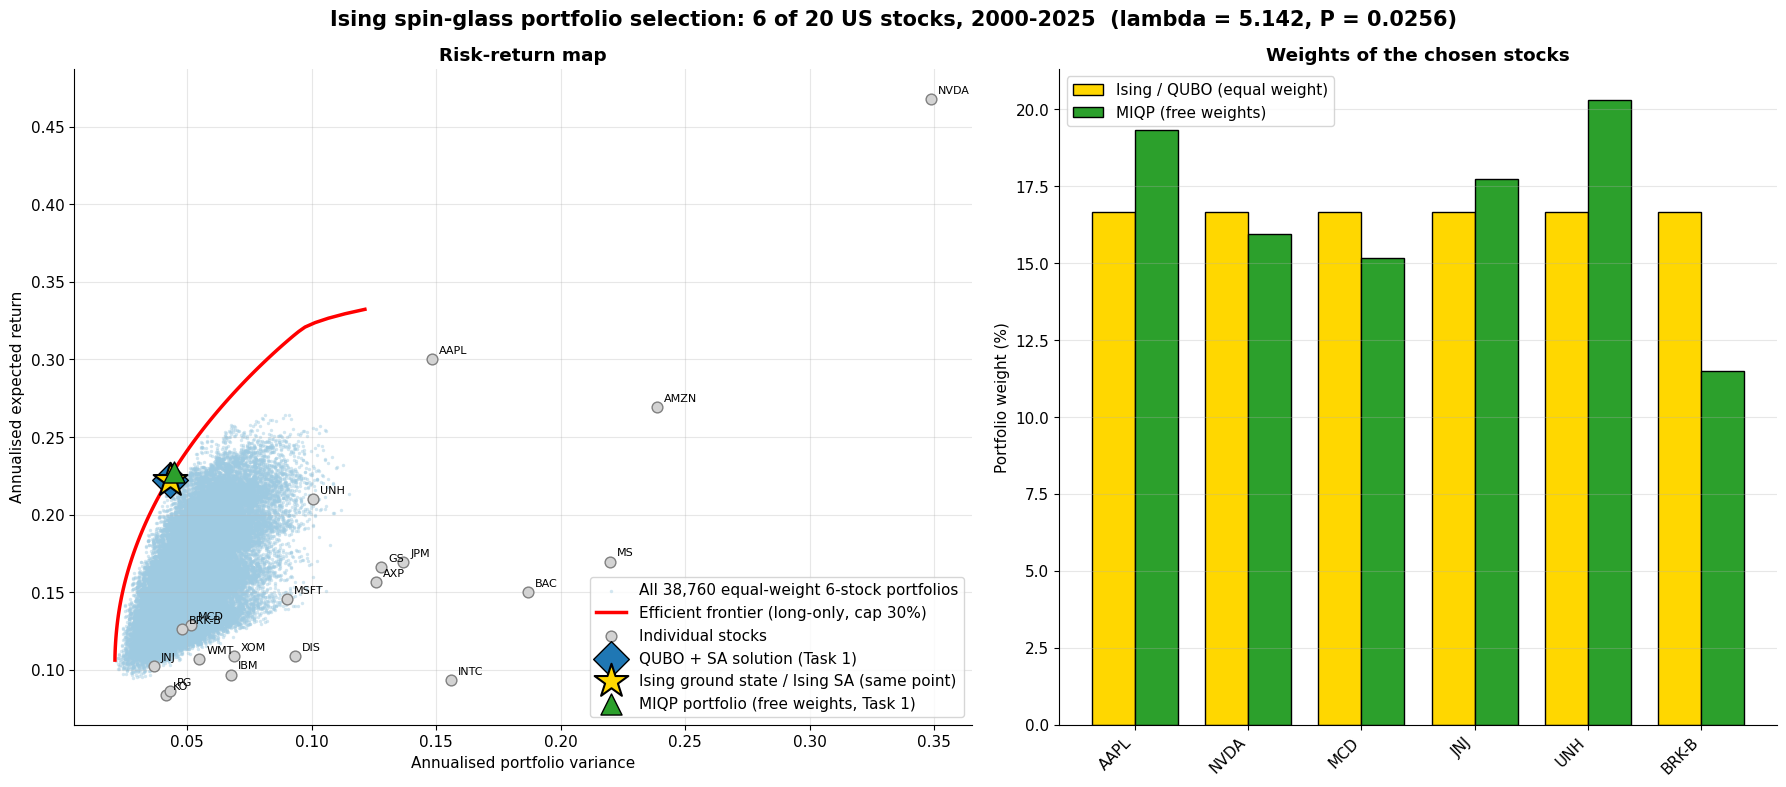

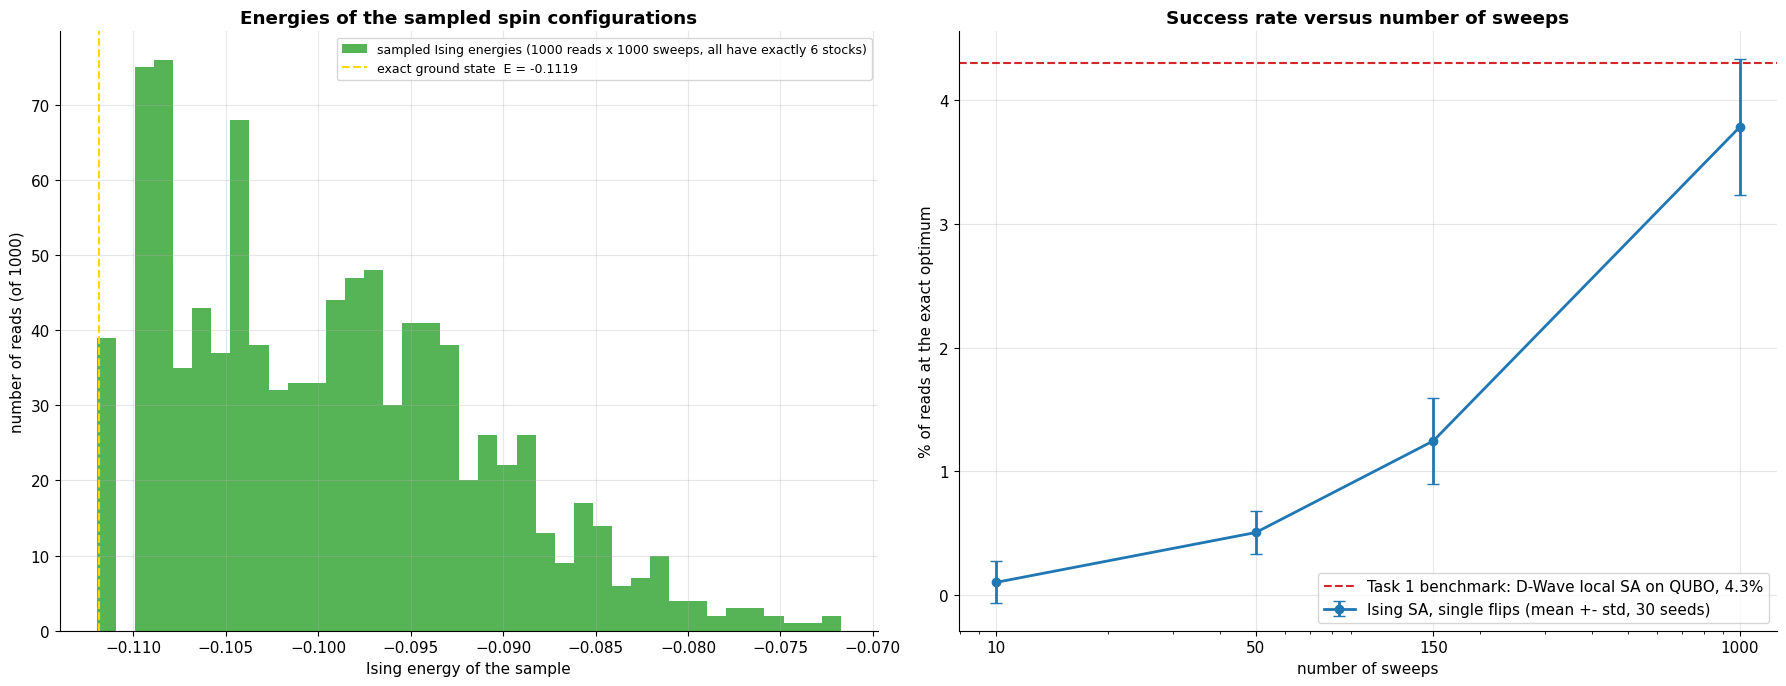

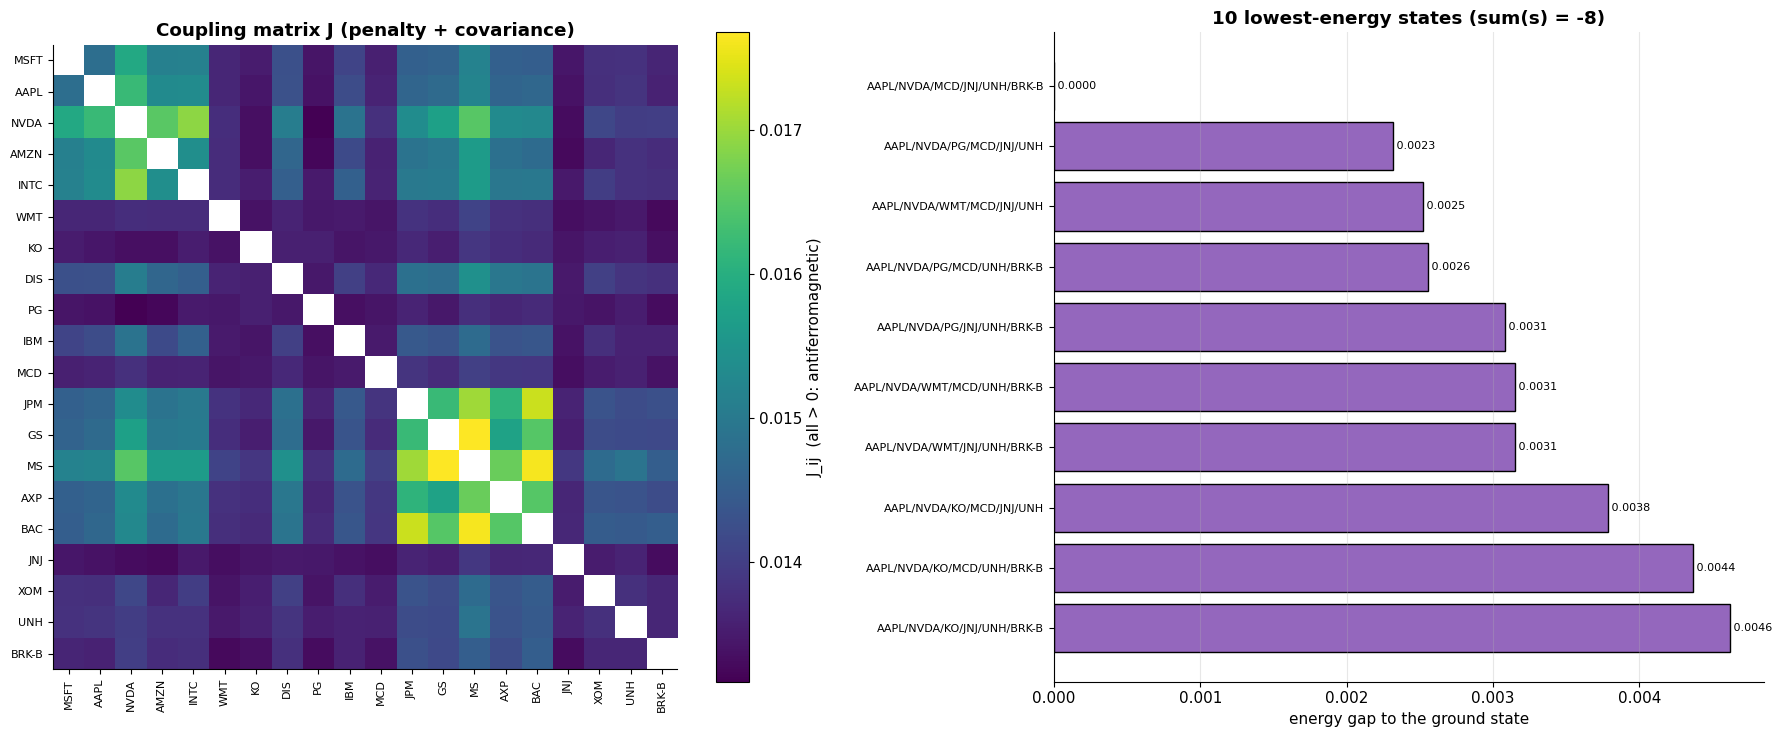

In [9]:
# TASK 2 | STEP 7 - Charts and spin-glass diagnostics
sig2 = np.diag(Sigma)
f_var, f_ret = frontier_points(mu, Sigma, MAX_W)
w_opt = w_ising_exact
sel = np.flatnonzero(w_opt)

# ---- Chart 1: risk-return map (Ising solution, QUBO solution, MIQP portfolio vs efficient frontier) + weights
fig, axes = plt.subplots(1, 2, figsize=(18, 8), gridspec_kw={"width_ratios": [1.25, 1]})
ax = axes[0]
rc = mu[combos].mean(axis=1); vc = Sigma[combos[:, :, None], combos[:, None, :]].sum(axis=(1, 2)) / K ** 2
ax.scatter(vc, rc, s=6, color="#9ecae1", alpha=0.45, linewidths=0, label=f"All {len(combos):,} equal-weight {K}-stock portfolios")
ax.plot(f_var, f_ret, color="red", lw=2.5, label=f"Efficient frontier (long-only, cap {MAX_W:.0%})", zorder=2)
ax.scatter(sig2, mu, s=60, color="lightgrey", edgecolor="grey", label="Individual stocks", zorder=3)
for i, t in enumerate(tickers):
    ax.annotate(t, (sig2[i], mu[i]), xytext=(5, 4), textcoords="offset points", fontsize=8)
r_, v_, _, _ = port_stats(w_qubo_sa)
ax.scatter(v_, r_, marker="D", s=330, color="#1f77b4", edgecolor="black", zorder=5, label="QUBO + SA solution (Task 1)")
r_, v_, _, _ = port_stats(w_ising_exact)
ax.scatter(v_, r_, marker="*", s=650, color="gold", edgecolor="black", linewidths=1.5, zorder=6, label="Ising ground state / Ising SA (same point)")
r_, v_, _, _ = port_stats(w_miqp)
ax.scatter(v_, r_, marker="^", s=230, color="#2ca02c", edgecolor="black", zorder=7, label="MIQP portfolio (free weights, Task 1)")
ax.set_xlabel("Annualised portfolio variance"); ax.set_ylabel("Annualised expected return"); ax.grid(True, alpha=0.3)
ax.legend(loc="lower right"); ax.set_title("Risk-return map", fontweight="bold")

ax = axes[1]
idx = np.array(sorted(set(sel) | set(np.flatnonzero(w_miqp)))); x_ = np.arange(len(idx)); bw = 0.38
ax.bar(x_ - bw / 2, w_ising_exact[idx] * 100, bw, color="gold", edgecolor="black", label="Ising / QUBO (equal weight)")
ax.bar(x_ + bw / 2, w_miqp[idx] * 100, bw, color="#2ca02c", edgecolor="black", label="MIQP (free weights)")
ax.set_xticks(x_); ax.set_xticklabels([tickers[i] for i in idx], rotation=45, ha="right")
ax.set_ylabel("Portfolio weight (%)"); ax.grid(True, axis="y", alpha=0.3); ax.legend(); ax.set_title("Weights of the chosen stocks", fontweight="bold")
fig.suptitle(f"Ising spin-glass portfolio selection: {K} of {N} US stocks, 2000-2025  (lambda = {LAMBDA:.3f}, P = {P:.4f})", fontsize=15, fontweight="bold")
plt.tight_layout(); savefig("ising_riskreturn_and_weights"); plt.show()

# ---- Chart 2: sampled Ising energies with the ground state marked + success rate versus number of sweeps
S_h, E_h, _ = RUNS[(1000, 1000)]
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
ax = axes[0]
bins = np.linspace(E_GS - 1e-4, np.percentile(E_h, 99), 40)
ax.hist(E_h, bins=bins, color="#2ca02c", alpha=0.8, label="sampled Ising energies (1000 reads x 1000 sweeps, all have exactly 6 stocks)")
ax.axvline(E_GS, color="gold", lw=1.5, ls="--", label=f"exact ground state  E = {E_GS:.4f}")
ax.set_xlabel("Ising energy of the sample"); ax.set_ylabel("number of reads (of 1000)"); ax.grid(True, alpha=0.3); ax.legend(loc="upper right", fontsize=9)
ax.set_title("Energies of the sampled spin configurations", fontweight="bold")
ax = axes[1]
ax.errorbar(sw.index, sw["% reads at optimum (mean)"], yerr=sw["std"], marker="o", lw=2, capsize=4, color="#1f77b4", label="Ising SA, single flips (mean +- std, 30 seeds)")
ax.axhline(4.3, color="#d62728", ls="--", lw=1.5, label="Task 1 benchmark: D-Wave local SA on QUBO, 4.3%")
ax.set_xscale("log"); ax.set_xticks(sw.index); ax.set_xticklabels(sw.index)
ax.set_xlabel("number of sweeps"); ax.set_ylabel("% of reads at the exact optimum"); ax.grid(True, alpha=0.3); ax.legend()
ax.set_title("Success rate versus number of sweeps", fontweight="bold")
plt.tight_layout(); savefig("ising_energy_histogram_and_sweeps"); plt.show()

# ---- Chart 3 (optional diagnostics): heat map of J and energy gaps of the 10 lowest states
fig, axes = plt.subplots(1, 2, figsize=(18, 7.5), gridspec_kw={"width_ratios": [1.1, 1]})
ax = axes[0]
im = ax.imshow(np.ma.masked_where(np.eye(N, dtype=bool), J), cmap="viridis", vmin=J[iu].min(), vmax=J[iu].max())
ax.set_xticks(range(N)); ax.set_xticklabels(tickers, rotation=90, fontsize=8); ax.set_yticks(range(N)); ax.set_yticklabels(tickers, fontsize=8)
plt.colorbar(im, ax=ax, label="J_ij  (all > 0: antiferromagnetic)"); ax.set_title("Coupling matrix J (penalty + covariance)", fontweight="bold")
ax = axes[1]
gaps = top10["Gap to ground state"].to_numpy()
ax.barh(range(10)[::-1], gaps, color="#9467bd", edgecolor="black")
ax.set_yticks(range(10)[::-1]); ax.set_yticklabels([s.replace(", ", "/") for s in top10["Spins up (stocks)"]], fontsize=8)
for yy, g in zip(range(10)[::-1], gaps):
    ax.text(g, yy, f" {g:.4f}", va="center", fontsize=8)
ax.set_xlabel("energy gap to the ground state"); ax.grid(True, axis="x", alpha=0.3); ax.set_title("10 lowest-energy states (sum(s) = -8)", fontweight="bold")
plt.tight_layout(); savefig("ising_J_heatmap_and_gaps"); plt.show()


## Comparison table

In [10]:
# TASK 2 | COMPARISON TABLE (Task 1 rows + Task 2 rows)
def row(method, w, extra=""):
    s = score(w)
    return {"Method": method, "Portfolio": ", ".join(tickers[i] for i in np.argsort(-w) if w[i] > 1e-6) + extra,
            "Return %": round(s["ret"], 2), "Vol %": round(s["vol"], 2), "Sharpe": round(s["sharpe"], 3), "Objective": round(s["obj"], 4)}
hit128 = RES["Ising SA, 128 chains x 150 sweeps"]["% reads at optimum"].mean()
hit1000 = RES["Ising SA, 1000 reads x 1000 sweeps"]["% reads at optimum"].mean()
hitp = RES["Ising SA + two-spin moves, 128 chains x 150 sweeps"]["% reads at optimum"].mean()
final = pd.DataFrame([
    row("MIQP (Gurobi, k = 6, free weights)  [Task 1]", w_miqp, "  (20.3 / 19.3 / 17.7 / 16.0 / 15.2 / 11.5%)"),
    row("QUBO + own SA (k = 6)  [Task 1]", w_qubo_sa, "  (16.67% each)"),
    {"Method": "QUBO + D-Wave local SA  [Task 1]", "Portfolio": "same six stocks (optimum in 4.3% of reads)", "Return %": 22.26, "Vol %": 20.75, "Sharpe": 1.073, "Objective": -0.1119},
    row("Ising + exhaustive search", w_ising_exact, "  (16.67% each)"),
    row("Ising + simulated annealing (single flips, 1000 x 1000)", w_ising_sa[(1000, 1000)], f"  (optimum in {hit1000:.1f}% of reads)"),
    row("Ising + simulated annealing (single flips, 128 x 150)", w_ising_sa[(128, 150)], f"  (optimum in {hit128:.1f}% of reads)"),
    row("Ising + simulated annealing (with two-spin moves, 128 x 150)", w_ising_pair, f"  (optimum in {hitp:.1f}% of reads)"),
    {"Method": "Ising + QPU / other (optional)", "Portfolio": "not run", "Return %": np.nan, "Vol %": np.nan, "Sharpe": np.nan, "Objective": np.nan},
]).set_index("Method")
display(final)
final.to_csv(f"{OUT_DIR}/ising_comparison_table.csv"); summ.to_csv(f"{OUT_DIR}/ising_solver_statistics.csv")
sw.to_csv(f"{OUT_DIR}/ising_sweeps_sensitivity.csv"); pen.to_csv(f"{OUT_DIR}/ising_penalty_sensitivity.csv"); top10.to_csv(f"{OUT_DIR}/ising_lowest_states.csv")


,Portfolio,Return %,Vol %,Sharpe,Objective
Method,,,,,
"MIQP (Gurobi, k = 6, free weights) [Task 1]","UNH, AAPL, JNJ, NVDA, MCD, BRK-B (20.3 / 19.3...",22.76,21.15,1.076,-0.1126
QUBO + own SA (k = 6) [Task 1],"AAPL, NVDA, MCD, JNJ, UNH, BRK-B (16.67% each)",22.26,20.75,1.073,-0.1119
QUBO + D-Wave local SA [Task 1],same six stocks (optimum in 4.3% of reads),22.26,20.75,1.073,-0.1119
Ising + exhaustive search,"AAPL, NVDA, MCD, JNJ, UNH, BRK-B (16.67% each)",22.26,20.75,1.073,-0.1119
"Ising + simulated annealing (single flips, 1000 x 1000)","AAPL, NVDA, MCD, JNJ, UNH, BRK-B (optimum in ...",22.26,20.75,1.073,-0.1119
"Ising + simulated annealing (single flips, 128 x 150)","AAPL, NVDA, MCD, JNJ, UNH, BRK-B (optimum in ...",22.26,20.75,1.073,-0.1119
"Ising + simulated annealing (with two-spin moves, 128 x 150)","AAPL, NVDA, MCD, JNJ, UNH, BRK-B (optimum in ...",22.26,20.75,1.073,-0.1119
Ising + QPU / other (optional),not run,NaN,NaN,NaN,NaN


## Step 8 - Conclusions

1. **Ising and QUBO are the same problem.** The Ising energy equals the QUBO energy on all 1,048,576 states (max difference 4e-15) and equals the Markowitz objective on all 38,760 six-stock states. The exact ground state is therefore the Task 1 portfolio: AAPL, NVDA, MCD, JNJ, UNH, BRK-B at 16.67% each (return 22.26%, volatility 20.75%, Sharpe 1.073, objective -0.1119, E_GS = -0.111866).
2. **Spin-glass picture.** All 190 couplings are positive (antiferromagnetic) on a fully connected graph, so the model is frustrated. About 90% of the mean coupling (P/2 = 0.0128 of 0.0142) is the penalty, which is identical for every pair; the covariance adds only a weak random part (std 0.0009). The 'exactly k stocks' rule is the fixed magnetisation sum(s) = -8.
3. **Solver behaviour.** Single-spin-flip Ising SA reaches the optimum in 1.3% of reads (128 x 150) and 3.8% (1000 x 1000), in line with the 4.3% of the D-Wave local SA in Task 1. With 128 x 150 its best read missed the optimum in 5 of 30 seeds (it returned the second-best portfolio, gap 0.0026). The Task 1 SA finds the optimum in 100% of reads because it also uses two-bit swap moves; Ising SA with the same two-spin moves also reaches 100%. The difference is therefore the move set, not Ising versus QUBO. More sweeps help (0.1% at 10 sweeps, 3.8% at 1000); a smaller penalty helps (16.2% at 0.5 P, 0.5% at 2 P) and the ground state stays the same six stocks for P between 0.5x and 2x.
4. **Weight model.** The MIQP's free weights give a slightly better objective (-0.1126 versus -0.1119; Sharpe 1.076 versus 1.073) than the equal-weight Ising/QUBO portfolio. Both choose the same six stocks.
5. **Scale.** At N = 20 every method finishes in well under a second (exhaustive search over 38,760 states: 0.03 s), so any advantage of Ising-type solvers could only show for larger universes.